#02 Modelling

In [35]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix,
                             classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [36]:
# Cell 2: Load the cleaned data saved by the EDA notebook
df = pd.read_csv("../data/jobs_clean.csv")
df["text_clean"] = df["text_clean"].fillna("")
df["country"] = df["country"].fillna("Unknown")

print(df.shape)
print(df["fraudulent"].value_counts())

(17599, 27)
fraudulent
0    16743
1      856
Name: count, dtype: int64


In [37]:
# Cell 3: Build features (only the columns the EDA showed to be useful)
flag_cols = ["has_company_profile", "has_company_logo", "has_questions",
             "telecommuting", "has_salary", "has_email", "has_phone"]

# Country: top 5 by count, everything else becomes "Other"
top_countries = df["country"].value_counts().head(5).index
df["country_grp"] = np.where(df["country"].isin(top_countries), df["country"], "Other")
country_dummies = pd.get_dummies(df["country_grp"], prefix="c", drop_first=True).astype(int)
country_cols = list(country_dummies.columns)

# Length features: raw (Models 1 and 2) and log (Model 3)
df["log_desc_length"] = np.log1p(df["desc_length"])
df["log_desc_words"] = np.log1p(df["desc_words"])

X = pd.concat([df[flag_cols + ["desc_length", "desc_words",
                               "log_desc_length", "log_desc_words",
                               "text_clean"]],
               country_dummies], axis=1)
y = df["fraudulent"]

print("Columns:", X.shape[1])
X.head()

Columns: 17


,has_company_profile,has_company_logo,has_questions,telecommuting,has_salary,has_email,has_phone,desc_length,desc_words,log_desc_length,log_desc_words,text_clean,c_DE,c_GB,c_GR,c_Other,c_US
0,1,1,0,0,0,0,0,905,124,6.809039,4.828314,"marketing intern we're food52, and we've creat...",0,0,0,0,1
1,1,1,0,0,0,0,0,2077,315,7.639161,5.755742,customer service - cloud video production 90 s...,0,0,0,1,0
2,1,1,0,0,0,0,0,355,50,5.874931,3.931826,commissioning machinery assistant (cma) valor ...,0,0,0,0,1
3,1,1,0,0,0,0,0,2600,346,7.863651,5.849325,account executive - washington dc our passion ...,0,0,0,0,1
4,1,1,1,0,0,0,1,1520,168,7.327123,5.129899,bill review manager spotsource solutions llc i...,0,0,0,0,1


In [38]:
# Cell 4: Train / validation / test split (stratified because of the imbalance)
# test = 20%, validation = 20%, train = 60%
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_train_full)

for name, part in [("train", y_tr), ("validation", y_val), ("test", y_test)]:
    print(name, len(part), "| fake rate:", round(part.mean() * 100, 2), "%")

train 10559 | fake rate: 4.87 %
validation 3520 | fake rate: 4.86 %
test 3520 | fake rate: 4.86 %


In [39]:
# Cell 5: Preprocessing builder
# TF-IDF on the text + scaled length columns + 0/1 flags and country dummies
def build_prep(len_cols):
    return ColumnTransformer([
        ("text", TfidfVectorizer(stop_words="english", max_features=2000,
                                 ngram_range=(1, 2), min_df=5, sublinear_tf=True),
         "text_clean"),
        ("len", StandardScaler(), len_cols),
        ("flags", "passthrough", flag_cols + country_cols),
    ])

raw_len_cols = ["desc_length", "desc_words"]
log_len_cols = ["log_desc_length", "log_desc_words"]

In [40]:
# Cell 6: Helper functions (adds validation PR-AUC)
def best_threshold(y_true, scores):
    """Cut-off with the best F1 (used on the validation set only)."""
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return t[np.argmax(f1)]

results = {}
predictions = {}

def evaluate(name, val_scores, test_scores):
    thr = best_threshold(y_val, val_scores)
    pred_val = (val_scores >= thr).astype(int)
    pred_test = (test_scores >= thr).astype(int)

    results[name] = {
        "Val PR-AUC": average_precision_score(y_val, val_scores),
        "Val F1": f1_score(y_val, pred_val),
        "Test Precision": precision_score(y_test, pred_test, zero_division=0),
        "Test Recall": recall_score(y_test, pred_test),
        "Test F1": f1_score(y_test, pred_test),
        "PR-AUC": average_precision_score(y_test, test_scores),
        "ROC-AUC": roc_auc_score(y_test, test_scores),
    }
    predictions[name] = pred_test
    print(name, "| threshold:", round(thr, 3))
    print(classification_report(y_test, pred_test, target_names=["Real", "Fake"], zero_division=0))

In [41]:
# Cell 7: Model 1 - Linear Regression (continuous score + threshold)
lin = Pipeline([("prep", build_prep(raw_len_cols)), ("model", LinearRegression())])
lin.fit(X_tr, y_tr)

evaluate("Linear Regression", lin.predict(X_val), lin.predict(X_test))

Linear Regression | threshold: 0.427
              precision    recall  f1-score   support

        Real       0.98      0.99      0.99      3349
        Fake       0.81      0.63      0.71       171

    accuracy                           0.97      3520
   macro avg       0.89      0.81      0.85      3520
weighted avg       0.97      0.97      0.97      3520



In [42]:
# Cell 8: Model 2 - Logistic Regression (tune C on the validation set)
best_C, best_ap = None, 0
for C in [0.01, 0.1, 1, 10, 100, 1000]:
    m = Pipeline([("prep", build_prep(raw_len_cols)),
                  ("model", LogisticRegression(C=C, max_iter=2000,
                                               class_weight="balanced",
                                               random_state=RANDOM_STATE))])
    m.fit(X_tr, y_tr)
    ap = average_precision_score(y_val, m.predict_proba(X_val)[:, 1])
    print("C =", C, "| validation PR-AUC =", round(ap, 4))
    if ap > best_ap:
        best_ap, best_C = ap, C

print("Best C:", best_C)

logit = Pipeline([("prep", build_prep(raw_len_cols)),
                  ("model", LogisticRegression(C=best_C, max_iter=2000,
                                               class_weight="balanced",
                                               random_state=RANDOM_STATE))])
logit.fit(X_tr, y_tr)

evaluate("Logistic Regression",
         logit.predict_proba(X_val)[:, 1], logit.predict_proba(X_test)[:, 1])

C = 0.01 | validation PR-AUC = 0.2945
C = 0.1 | validation PR-AUC = 0.5508
C = 1 | validation PR-AUC = 0.7843
C = 10 | validation PR-AUC = 0.8354
C = 100 | validation PR-AUC = 0.827
C = 1000 | validation PR-AUC = 0.8234
Best C: 10
Logistic Regression | threshold: 0.579
              precision    recall  f1-score   support

        Real       0.99      0.98      0.99      3349
        Fake       0.69      0.81      0.75       171

    accuracy                           0.97      3520
   macro avg       0.84      0.90      0.87      3520
weighted avg       0.98      0.97      0.97      3520



In [43]:
# Cell 9: Model 3 - Logarithmic Regression
# y = a + b1*ln(1 + length) + b2*ln(1 + words) + other features (log-transformed lengths)
logreg = Pipeline([("prep", build_prep(log_len_cols)), ("model", LinearRegression())])
logreg.fit(X_tr, y_tr)

evaluate("Logarithmic Regression", logreg.predict(X_val), logreg.predict(X_test))

Logarithmic Regression | threshold: 0.438
              precision    recall  f1-score   support

        Real       0.98      0.99      0.99      3349
        Fake       0.84      0.63      0.72       171

    accuracy                           0.98      3520
   macro avg       0.91      0.81      0.86      3520
weighted avg       0.97      0.98      0.97      3520



In [44]:
# Cell 10: Compare all models
comparison = pd.DataFrame(results).T.round(4)
comparison

,Val PR-AUC,Val F1,Test Precision,Test Recall,Test F1,PR-AUC,ROC-AUC
Linear Regression,0.8228,0.7826,0.8060,0.6316,0.7082,0.7925,0.9554
Logistic Regression,0.8354,0.7772,0.6915,0.8129,0.7473,0.8408,0.9809
Logarithmic Regression,0.8253,0.7886,0.8438,0.6316,0.7224,0.7924,0.9551


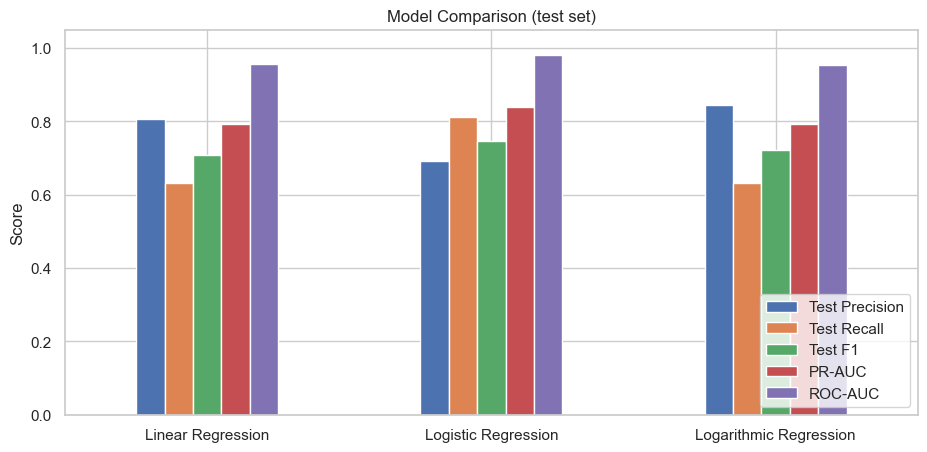

In [45]:
# Cell 11: Comparison plot
comparison[["Test Precision", "Test Recall", "Test F1", "PR-AUC", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5), rot=0)
plt.title("Model Comparison (test set)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

In [46]:
# Cell 12: Choose the best model by validation PR-AUC (does not depend on the threshold)
best_name = comparison["Val PR-AUC"].idxmax()
print("Best model:", best_name)
comparison.loc[best_name]

Best model: Logistic Regression


Val PR-AUC        0.8354
Val F1            0.7772
Test Precision    0.6915
Test Recall       0.8129
Test F1           0.7473
PR-AUC            0.8408
ROC-AUC           0.9809
Name: Logistic Regression, dtype: float64

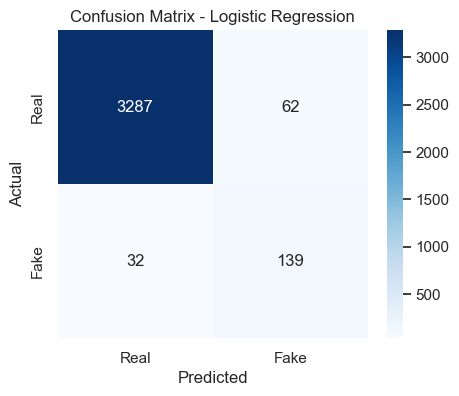

In [47]:
# Cell 13: Confusion matrix of the best model
cm = confusion_matrix(y_test, predictions[best_name])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

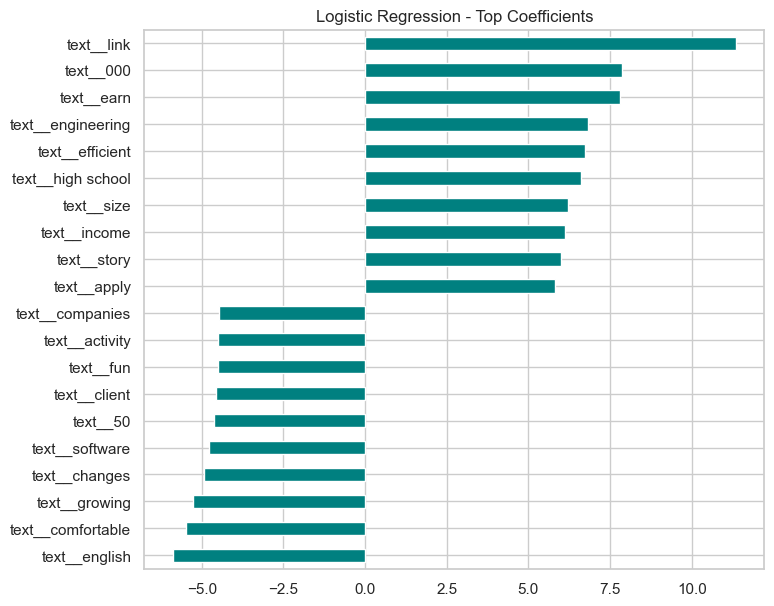

In [48]:
# Cell 14: Top features of Logistic Regression
names = logit.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logit.named_steps["model"].coef_[0], index=names).sort_values()

top = pd.concat([coef.head(10), coef.tail(10)])
top.plot(kind="barh", figsize=(8, 7), color="teal")
plt.title("Logistic Regression - Top Coefficients")
plt.show()